# Final project: Einramhof Lena

In [1]:
import numpy as np
import finufft 
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import plotly.graph_objects as go
from scipy.ndimage import map_coordinates

In [2]:
#set up initial field using specified ICs and random seed 

#compute the power spectrum with a value of alpha 
def calc_powerspectrum(k, alpha, amplitude):
    return amplitude* k**(-alpha)

#generate a gaussian field 
def generate_gaussian_field(Points, Length, alpha=1.5, amplitude=25, seed=42):
    #define parameters
    dx = Length / Points

    #create k vectors
    kx = 2*np.pi* np.fft.fftfreq(Points, d=dx)
    KX, KY, KZ = np.meshgrid(kx, kx, kx, indexing='ij')
    K = np.sqrt(KX**2 + KY**2 + KZ**2)
    K[0, 0, 0] = 1.0 #avoid division by zero at k=0

    #compute power spectrum on the grid
    Pk = calc_powerspectrum(K, alpha, amplitude)
    Pk[0, 0, 0] = 0.0 #set k=0 mode to zero (no mean)

    #define amplitude 
    amplitude = np.sqrt(Pk)
    rng = np.random.default_rng(seed)

    #generate white noise (random gaussian field in realspace)
    noise = (rng.normal(0, 1, (Points,Points, Points)) + 1j * rng.normal(0, 1, (Points,Points, Points)))

    #apply powerlaw with normalization
    norm = 1.0/(2*np.pi)**(-1.5)  
    cell_volume = dx**3
    delta_k = amplitude * noise/cell_volume**(1/2)

    d_phi_x = 1j*KX * (delta_k/(-K**2))
    d_phi_y = 1j*KY * (delta_k/(-K**2))
    d_phi_z = 1j*KZ * (delta_k/(-K**2))

    d_phi_xx = -KX**2 * (delta_k/(-K**2))
    d_phi_yy = -KY**2 * (delta_k/(-K**2))
    d_phi_zz = -KZ**2 * (delta_k/(-K**2))
    d_phi_xy = -KX*KY * (delta_k/(-K**2))
    d_phi_xz = -KX*KZ * (delta_k/(-K**2))
    d_phi_yz = -KY*KZ * (delta_k/(-K**2))


    # the generated true field with normalization back into realspace
    f = norm * np.fft.ifftn(delta_k).real
    d_phi_x = norm*np.fft.ifftn(d_phi_x).real
    d_phi_y = norm*np.fft.ifftn(d_phi_y).real
    d_phi_z = norm*np.fft.ifftn(d_phi_z).real
    d_phi_xx = norm*np.fft.ifftn(d_phi_xx).real
    d_phi_yy = norm*np.fft.ifftn(d_phi_yy).real
    d_phi_zz = norm*np.fft.ifftn(d_phi_zz).real
    d_phi_xy = norm*np.fft.ifftn(d_phi_xy).real
    d_phi_xz = norm*np.fft.ifftn(d_phi_xz).real
    d_phi_yz = norm*np.fft.ifftn(d_phi_yz).real

    return f, (d_phi_x, d_phi_y, d_phi_z), (d_phi_xx, d_phi_yy, d_phi_zz, d_phi_xy, d_phi_xz, d_phi_yz)

In [3]:
#ZA

#calculate the time of shell-crossing 
def calculate_shellcrossing(d2phi, a_max, da):
    d_phi_xx, d_phi_yy, d_phi_zz, d_phi_xy, d_phi_xz, d_phi_yz = d2phi
    
    #compute det(J) for different times until it is <= 0 
    for d in np.arange(0, a_max, da):
        Jxx = 1 - d*d_phi_xx
        Jyy = 1 - d*d_phi_yy
        Jzz = 1 - d*d_phi_zz
        Jxy = -d*d_phi_xy
        Jxz = -d*d_phi_xz
        Jyz = -d*d_phi_yz

        det_J = Jxx*(Jyy*Jzz - Jyz**2)- Jxy*(Jxy*Jzz - Jyz*Jxz) + Jxz*(Jxy*Jyz - Jyy*Jxz)

        if np.min(det_J) <= 0:
            break

    return d

#displace the particles according to the ZA map 
def displace_particles(D, d_phi_x, d_phi_y, d_phi_z, particles_grid_x, particles_grid_y, particles_grid_z, L):
    x = particles_grid_x - D * d_phi_x
    y = particles_grid_y - D * d_phi_y
    z = particles_grid_z - D * d_phi_z
    return x%L, y%L, z%L

In [4]:
#compute the gravitational acceleration using NUFFT 
def calc_acc_nufft(x, y, z, N, eps=1e-4):
    #set up the weights
    w = np.ones(len(x), dtype=np.complex128)/len(x)
    #transform the field
    f = finufft.nufft3d1(x*2*np.pi, y*2*np.pi, z*2*np.pi, w, (N, N, N), eps=eps)
    
    #set up wave modes
    kx = 2 * np.pi * (np.arange(N)-N//2)
    KX, KY, KZ = np.meshgrid(kx, kx, kx, indexing="ij")
    K = np.sqrt(KX**2 + KY**2 + KZ**2)
    K[N//2, N//2, N//2] = 1.0 

    #A=-grad(phi) -> -ik/k^2*delta_k
    fx = f * (-1j*KX/K**2)
    fy = f * (-1j*KY/K**2)
    fz = f * (-1j*KZ/K**2)

    fx[N//2, N//2, N//2] = 0.0
    fy[N//2, N//2, N//2] = 0.0
    fz[N//2, N//2, N//2] = 0.0

    #fourier transform back 
    acc_x = finufft.nufft3d2(x*2*np.pi, y*2*np.pi, z*2*np.pi, fx, eps=eps)
    acc_y = finufft.nufft3d2(x*2*np.pi, y*2*np.pi, z*2*np.pi, fy, eps=eps)
    acc_z = finufft.nufft3d2(x*2*np.pi, y*2*np.pi, z*2*np.pi, fz, eps=eps)

    return np.column_stack((acc_x.real, acc_y.real, acc_z.real))


In [5]:
#perform one leapfrog step 
def step(X, V, a, da, a_end, N, L):
    t_begin = 2-2/np.sqrt(a)
    t_end = 2-2/np.sqrt(a_end)

    a_mid = 1/(1-(t_begin+t_end)/4)**2
    dt = t_end-t_begin

    acc = calc_acc_nufft(X[:, 0] / L, X[:, 1] / L, X[:, 2] / L, N)

    X = X + 0.5*dt * V
    V = V + dt * 3.0/2.0 * a_mid * acc
    X = X + 0.5*dt * V
    
    X = X % L
    a = a+da

    return (X, V, a)


In [6]:
#run the simulation 
def run_simulation(dphi, d2phi, N, L, a_end, dt_target=0.01, type="leapfrog", a_search_max=5):
    d_phi_x, d_phi_y, d_phi_z = dphi
    
    dx = L / N

    #construct particle grid 
    particles_x = (np.arange(0, N, 1) + 0.5) * dx
    particles_y = (np.arange(0, N, 1) + 0.5) * dx
    particles_z = (np.arange(0, N, 1) + 0.5) * dx
    particles_grid_x, particles_grid_y, particles_grid_z = np.meshgrid(particles_x, particles_y, particles_z, indexing="ij")

    #compute the time of shell crossing and time to switch to leapfrog
    d_shellcrossing = calculate_shellcrossing(d2phi, a_search_max, da=0.01)
    a_switch = 0.5*d_shellcrossing
    print("Shellcrossing time:", d_shellcrossing)
    print("Switch to leapfrog:", a_switch)

    #only linear displacement
    if type=="zeldovich" or a_switch >= a_end:
        #displace particles until the end
        displaced_x, displaced_y, displaced_z = displace_particles(a_end, d_phi_x, d_phi_y, d_phi_z, particles_grid_x, particles_grid_y, particles_grid_z, L)
        X = np.column_stack((displaced_x.ravel(), displaced_y.ravel(), displaced_z.ravel()))
        #compute velocities
        V_x = a_end**(3/2) * (-d_phi_x) 
        V_y = a_end**(3/2) * (-d_phi_y) 
        V_z = a_end**(3/2) * (-d_phi_z) 
        V = np.column_stack((V_x.ravel(), V_y.ravel(), V_z.ravel()))
        return X, V

    #do ZA+Leapfrog
    if type=="leapfrog":
        #displace particles until a_switch 
        displaced_x, displaced_y, displaced_z = displace_particles(a_switch, d_phi_x, d_phi_y, d_phi_z, particles_grid_x, particles_grid_y, particles_grid_z, L)
        X = np.column_stack((displaced_x.ravel(), displaced_y.ravel(), displaced_z.ravel()))
        #compute velocities
        V_x = a_switch**(3/2) * (-d_phi_x) 
        V_y = a_switch**(3/2) * (-d_phi_y) 
        V_z = a_switch**(3/2) * (-d_phi_z) 
        V = np.column_stack((V_x.ravel(), V_y.ravel(), V_z.ravel()))

        #perform leapfrog steps until the end 
        a = a_switch
        istep = 0
        while a < a_end:
            da = dt_target * a**1.5   
            a_next = np.minimum(a + da, a_end)
            (X, V, a) = step(X, V, a, da, a_next, N, L)
            istep += 1
        print("Total leapfrog steps taken:", istep)

        return X, V

    else:
        print("Error. Try 'leapfrog' or 'zeldovich' as type.")

### Validate power spectrum

In [7]:
#compute the azimuthally averaged powerspectrum in 3D
def compute_powerspectrum3d(field, L, N):
    #define parameters
    dx = L / N
    kf=2*np.pi/L

    #create k vectors
    kx = 2*np.pi* np.fft.fftfreq(N, d=dx)
    KX, KY, KZ = np.meshgrid(kx, kx, kx, indexing='ij')
    K = np.sqrt(KX**2 + KY**2 + KZ**2)
    K[0, 0, 0] = 1.0 #avoid division by zero at k=0

    fk = np.fft.fftn(field) 
    Pk = np.abs(fk)**2 / N**3
    Pk[0, 0, 0] = 0.0 #set k=0 mode to zero (no mean)
    K[0, 0, 0] = 0.0 

    k_bins = np.arange(kf, K.max(), kf)
    k_center = 0.5 * (k_bins[:-1] + k_bins[1:])

    #bin azimuthally 
    Pk_avg = np.zeros(len(k_center))
    
    for i in range(len(k_center)):
        mask = (K >= k_bins[i]) & (K < k_bins[i+1])
        if np.sum(mask) > 0:
            Pk_avg[i] = np.mean(Pk[mask])

    return k_center, Pk_avg

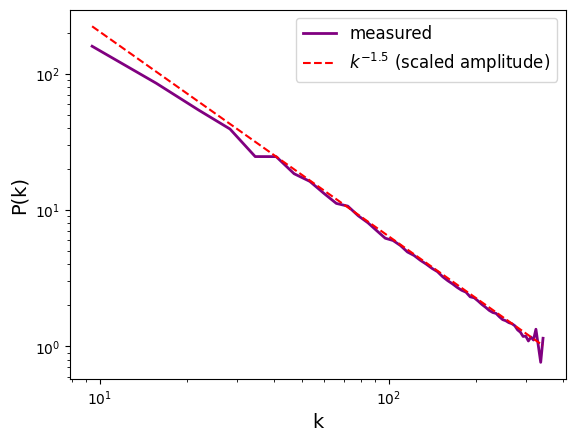

In [9]:
#compare the power spectrum of the field to the theoretical solution k^-alpha
L=1
N=64
alpha = 1.5

f, dphi, d2phi = generate_gaussian_field(N, L)
k, Pk = compute_powerspectrum3d(f, L, N)

plt.loglog(k, Pk, color="purple",lw=2, label="measured")
plt.loglog(k, k**(-alpha) * (Pk[5]/k[5]**(-alpha)), linestyle="--", color="red", label=r"$k^{-1.5}$ (scaled amplitude)")
plt.legend(fontsize=12)
plt.xlabel("k", fontsize=14)
plt.ylabel("P(k)", fontsize=14)
plt.show()

### 1D plane wave evolution

In [36]:
#set up a single-mode plane wave
L=1
N=64
dx = L / N

#construct the particle grid
particles_x = (np.arange(0, N, 1) + 0.5) * dx
particles_y = (np.arange(0, N, 1) + 0.5) * dx
particles_z = (np.arange(0, N, 1) + 0.5) * dx
particles_grid_x, particles_grid_y, particles_grid_z = np.meshgrid(particles_x, particles_y, particles_z, indexing="ij")

#set the x component to a sine wave and all other components to 0 
d_phi_x = np.sin(2*np.pi*(particles_grid_x - 0.25)) / (2*np.pi)
d_phi_y = np.zeros_like(particles_grid_x)
d_phi_z = np.zeros_like(particles_grid_x)
d_phi_xx = np.cos(2*np.pi*(particles_grid_x - 0.25))
d_phi_yy = np.zeros_like(particles_grid_x)
d_phi_zz = np.zeros_like(particles_grid_x)
d_phi_xy = np.zeros_like(particles_grid_x)
d_phi_xz = np.zeros_like(particles_grid_x)
d_phi_yz = np.zeros_like(particles_grid_x)

dphi=(d_phi_x, d_phi_y, d_phi_z)
d2phi = (d_phi_xx, d_phi_yy, d_phi_zz, d_phi_xy, d_phi_xz, d_phi_yz)

In [37]:
#evolve the plane wave to different a using leapfrog
x_1d_01, v_1d_01 = run_simulation(dphi, d2phi, N, L, 0.1, type="leapfrog")
x_1d_05, v_1d_05 = run_simulation(dphi, d2phi, N, L, 0.5, type="leapfrog")
x_1d_1, v_1d_1 = run_simulation(dphi, d2phi, N, L, 1, type="leapfrog")
x_1d_5, v_1d_5 = run_simulation(dphi, d2phi, N, L, 5, type="leapfrog")

Shellcrossing time: 1.01
Switch to leapfrog: 0.505
Shellcrossing time: 1.01
Switch to leapfrog: 0.505
Shellcrossing time: 1.01
Switch to leapfrog: 0.505
Total leapfrog steps taken: 82
Shellcrossing time: 1.01
Switch to leapfrog: 0.505
Total leapfrog steps taken: 194


In [38]:
#evolve the plane wave to different a using ZA
x_1d_01_za, v_1d_01_za = run_simulation(dphi, d2phi, N, L, 0.1, type="zeldovich")
x_1d_05_za, v_1d_05_za = run_simulation(dphi, d2phi, N, L, 0.5, type="zeldovich")
x_1d_1_za, v_1d_1_za = run_simulation(dphi, d2phi, N, L, 1, type="zeldovich")
x_1d_5_za, v_1d_5_za = run_simulation(dphi, d2phi, N, L, 5, type="zeldovich")

Shellcrossing time: 1.01
Switch to leapfrog: 0.505
Shellcrossing time: 1.01
Switch to leapfrog: 0.505
Shellcrossing time: 1.01
Switch to leapfrog: 0.505
Shellcrossing time: 1.01
Switch to leapfrog: 0.505


In [39]:
#reshape the solutions onto a grid  
X_grid_01 = x_1d_01.reshape(N, N, N, 3)
V_grid_01 = v_1d_01.reshape(N, N, N, 3)
X_grid_05 = x_1d_05.reshape(N, N, N, 3)
V_grid_05 = v_1d_05.reshape(N, N, N, 3)
X_grid_1 = x_1d_1.reshape(N, N, N, 3)
V_grid_1 = v_1d_1.reshape(N, N, N, 3)
X_grid_5 = x_1d_5.reshape(N, N, N, 3)
V_grid_5 = v_1d_5.reshape(N, N, N, 3)

X_grid_01_za = x_1d_01_za.reshape(N, N, N, 3)
V_grid_01_za = v_1d_01_za.reshape(N, N, N, 3)
X_grid_05_za = x_1d_05_za.reshape(N, N, N, 3)
V_grid_05_za = v_1d_05_za.reshape(N, N, N, 3)
X_grid_1_za = x_1d_1_za.reshape(N, N, N, 3)
V_grid_1_za = v_1d_1_za.reshape(N, N, N, 3)
X_grid_5_za = x_1d_5_za.reshape(N, N, N, 3)
V_grid_5_za = v_1d_5_za.reshape(N, N, N, 3)

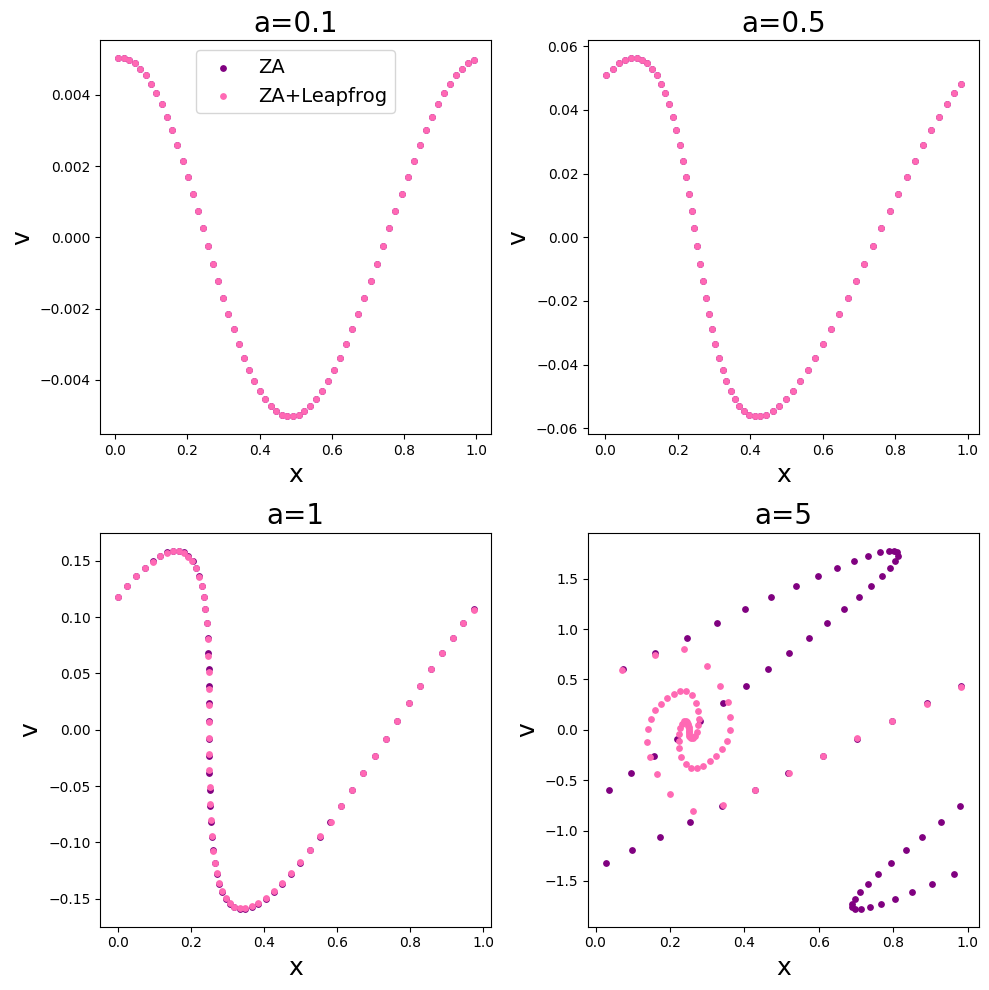

In [40]:
#plot the results 
fig, ax = plt.subplots(2, 2, figsize=(10, 10))

ax[0, 0].scatter(X_grid_01_za[:, 0, 0, 0], V_grid_01_za[:, 0, 0, 0], s=15, color="purple", label="ZA")
ax[0, 0].scatter(X_grid_01[:, 0, 0, 0], V_grid_01[:, 0, 0, 0], s=15, color="hotpink", label="ZA+Leapfrog")
ax[0, 0].set_xlabel("x", fontsize=18)
ax[0, 0].set_ylabel("v", fontsize=18)
ax[0, 0].legend(fontsize=14)
ax[0, 0].set_title("a=0.1", fontsize=20)

ax[0, 1].scatter(X_grid_05_za[:, 0, 0, 0], V_grid_05_za[:, 0, 0, 0], s=15, color="purple", label="ZA")
ax[0, 1].scatter(X_grid_05[:, 0, 0, 0], V_grid_05[:, 0, 0, 0], s=15, color="hotpink", label="ZA+Leapfrog")
ax[0, 1].set_xlabel("x", fontsize=18)
ax[0, 1].set_ylabel("v", fontsize=18)
ax[0, 1].set_title("a=0.5", fontsize=20)

ax[1, 0].scatter(X_grid_1_za[:, 0, 0, 0], V_grid_1_za[:, 0, 0, 0], s=15, color="purple", label="ZA")
ax[1, 0].scatter(X_grid_1[:, 0, 0, 0], V_grid_1[:, 0, 0, 0], s=15, color="hotpink", label="ZA+Leapfrog")
ax[1, 0].set_xlabel("x", fontsize=18)
ax[1, 0].set_ylabel("v", fontsize=18)
ax[1, 0].set_title("a=1", fontsize=20)

ax[1, 1].scatter(X_grid_5_za[:, 0, 0, 0], V_grid_5_za[:, 0, 0, 0], s=15, color="purple", label="ZA")
ax[1, 1].scatter(X_grid_5[:, 0, 0, 0], V_grid_5[:, 0, 0, 0], s=15, color="hotpink", label="ZA+Leapfrog")
ax[1, 1].set_xlabel("x", fontsize=18)
ax[1, 1].set_ylabel("v", fontsize=18)
ax[1, 1].set_title("a=5", fontsize=20)

plt.tight_layout()
plt.show()

### PM force resolution for a plane wave

In [41]:
#compute the exact acceleration using a sorting algorithm 
def calc_acc_sorted_1d(X):
    #set acceleration to 0 initially
    acc = np.zeros_like(X)
    #create rank indices
    rank = np.arange(len(X))
    #wrap X to be inside [0,1)
    Xs = np.fmod(1.0 + X, 1.0)
    #compute the mean
    Xm = np.mean(Xs)
    #get the sorting order
    sorted_ind = np.argsort(Xs)
    #equation 7.55
    acc[sorted_ind] = (rank + 0.5)/len(X) - (Xs[sorted_ind] - Xm) - 0.5
    return acc

#put the sorted 1d acceleration onto a 3d field that can be used by run_simulation
def calc_acc_exact_3d(X, N):
    #set up grid with 0 
    X_grid = X[:,0].reshape(N, N, N)
    acc_x = np.zeros_like(X_grid)
    #insert computed acceleration in x
    for j in range(N):
        for k in range(N):
            acc_x[:, j, k] = calc_acc_sorted_1d(X_grid[:, j, k])
    acc = np.zeros_like(X)
    acc[:, 0] = acc_x.ravel()
    return acc

#compute the leapfrog step using the exact acceleration
def step_exact(X, V, a, da, a_end, N):
    t_begin = 2-2/np.sqrt(a)
    t_end = 2-2/np.sqrt(a_end)
    a_mid = 1/(1-(t_begin+t_end)/4)**2
    dt = t_end-t_begin

    X = X + 0.5*dt*V
    V = V - dt*1.5*a_mid*calc_acc_exact_3d(X, N)
    X = X + 0.5*dt*V
    X = X % 1.0
    a = a + da
    return (X, V, a)

#run the simulation with the exact step
def run_simulation_exact(dphi, d2phi, N, L, a_end, dt_target=0.01, type="leapfrog", a_search_max=50.0):
    d_phi_x, d_phi_y, d_phi_z = dphi
    
    dx = L / N

    particles_x = (np.arange(0, N, 1) + 0.5) * dx
    particles_y = (np.arange(0, N, 1) + 0.5) * dx
    particles_z = (np.arange(0, N, 1) + 0.5) * dx

    particles_grid_x, particles_grid_y, particles_grid_z = np.meshgrid(particles_x, particles_y, particles_z, indexing="ij")

    d_shellcrossing = calculate_shellcrossing(d2phi, a_search_max, da=0.01)
    a_switch = 0.5*d_shellcrossing
    print("Shellcrossing time:", d_shellcrossing)
    print("Switch to leapfrog:", a_switch)

    if type=="zeldovich" or a_switch >= a_end:
        displaced_x, displaced_y, displaced_z = displace_particles(a_end, d_phi_x, d_phi_y, d_phi_z, particles_grid_x, particles_grid_y, particles_grid_z, L)
        X = np.column_stack((displaced_x.ravel(), displaced_y.ravel(), displaced_z.ravel()))
        V_x = a_end**(3/2) * (-d_phi_x) 
        V_y = a_end**(3/2) * (-d_phi_y) 
        V_z = a_end**(3/2) * (-d_phi_z) 
        V = np.column_stack((V_x.ravel(), V_y.ravel(), V_z.ravel()))
        return X, V

    displaced_x, displaced_y, displaced_z = displace_particles(a_switch, d_phi_x, d_phi_y, d_phi_z, particles_grid_x, particles_grid_y, particles_grid_z, L)
    X = np.column_stack((displaced_x.ravel(), displaced_y.ravel(), displaced_z.ravel()))
    V_x = a_switch**(3/2) * (-d_phi_x) 
    V_y = a_switch**(3/2) * (-d_phi_y) 
    V_z = a_switch**(3/2) * (-d_phi_z) 
    V = np.column_stack((V_x.ravel(), V_y.ravel(), V_z.ravel()))

    a = a_switch
    istep = 0
    while a < a_end:
        da = dt_target * a**1.5   
        a_next = np.minimum(a + da, a_end)
        (X, V, a) = step_exact(X, V, a, da, a_next, N)
        istep += 1
    print("Total leapfrog steps taken:", istep)

    return X, V

In [ ]:
#store the results in arrays so this has to be only computed once 
x_res_exact = []
v_res_exact = []

x_res = []
v_res= []

#compute both for different grid/particle resolutions 
for N_test in [32, 64, 128, 256]:
    dx = L / N_test

    particles_x = (np.arange(0, N_test, 1) + 0.5) * dx
    particles_y = (np.arange(0, N_test, 1) + 0.5) * dx
    particles_z = (np.arange(0, N_test, 1) + 0.5) * dx

    particles_grid_x, particles_grid_y, particles_grid_z = np.meshgrid(particles_x, particles_y, particles_z, indexing="ij")

    d_phi_x = np.sin(2*np.pi*(particles_grid_x - 0.25)) / (2*np.pi)
    d_phi_y = np.zeros_like(particles_grid_x)
    d_phi_z = np.zeros_like(particles_grid_x)
    d_phi_xx = np.cos(2*np.pi*(particles_grid_x - 0.25))
    d_phi_yy = np.zeros_like(particles_grid_x)
    d_phi_zz = np.zeros_like(particles_grid_x)
    d_phi_xy = np.zeros_like(particles_grid_x)
    d_phi_xz = np.zeros_like(particles_grid_x)
    d_phi_yz = np.zeros_like(particles_grid_x)

    dphi=(d_phi_x, d_phi_y, d_phi_z)
    d2phi = (d_phi_xx, d_phi_yy, d_phi_zz, d_phi_xy, d_phi_xz, d_phi_yz)    
    
    x_1d_5_exact, v_1d_5_exact = run_simulation_exact(dphi, d2phi, N_test, L, 5, type="leapfrog")
    x_1d_5, v_1d_5 = run_simulation(dphi, d2phi, N_test, L, 5, type="leapfrog")
    x_res_exact.append(x_1d_5_exact)
    v_res_exact.append(v_1d_5_exact)
    x_res.append(x_1d_5)
    v_res.append(v_1d_5)

In [ ]:
#save the results 
np.save("x_res_exact.npy", np.array(x_res_exact, dtype=object))
np.save("v_res_exact.npy", np.array(v_res_exact, dtype=object))

np.save("x_res.npy", np.array(x_res, dtype=object))
np.save("v_res.npy", np.array(v_res, dtype=object))

In [10]:
#load the results
x_res_exact = np.load("x_res_exact.npy", allow_pickle=True)
v_res_exact = np.load("v_res_exact.npy", allow_pickle=True)

x_res = np.load("x_res.npy", allow_pickle=True)
v_res = np.load("v_res.npy", allow_pickle=True)

In [11]:
#reshape the results onto a grid
X_grid_32_exact = x_res_exact[0].reshape(32, 32, 32, 3)
V_grid_32_exact = v_res_exact[0].reshape(32, 32, 32, 3)
X_grid_64_exact = x_res_exact[1].reshape(64, 64, 64, 3)
V_grid_64_exact = v_res_exact[1].reshape(64, 64, 64, 3)
X_grid_128_exact = x_res_exact[2].reshape(128, 128, 128, 3)
V_grid_128_exact = v_res_exact[2].reshape(128, 128, 128, 3)
X_grid_256_exact = x_res_exact[3].reshape(256, 256, 256, 3)
V_grid_256_exact = v_res_exact[3].reshape(256, 256, 256, 3)

X_grid_32 = x_res[0].reshape(32, 32, 32, 3)
V_grid_32 = v_res[0].reshape(32, 32, 32, 3)
X_grid_64 = x_res[1].reshape(64, 64, 64, 3)
V_grid_64 = v_res[1].reshape(64, 64, 64, 3)
X_grid_128 = x_res[2].reshape(128, 128, 128, 3)
V_grid_128 = v_res[2].reshape(128, 128, 128, 3)
X_grid_256 = x_res[3].reshape(256, 256, 256, 3)
V_grid_256 = v_res[3].reshape(256, 256, 256, 3)

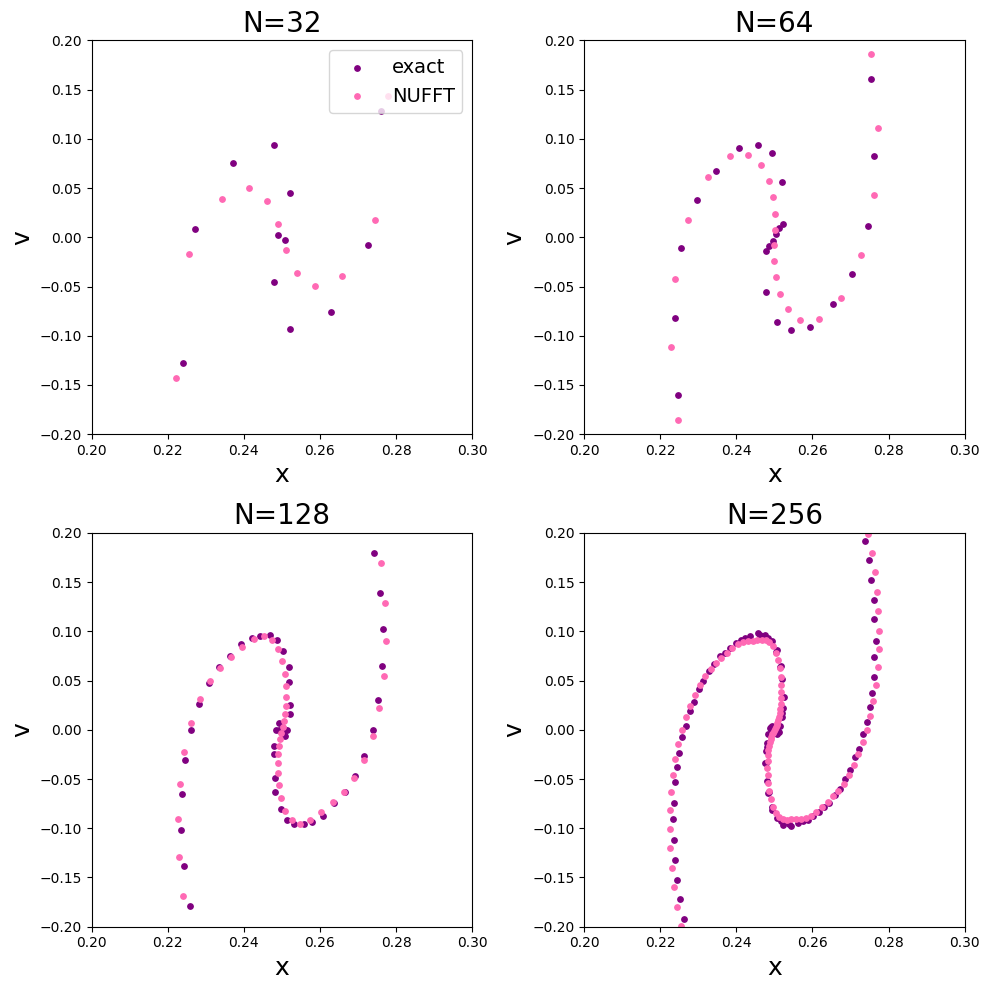

In [12]:
#plot the results
fig, ax = plt.subplots(2, 2, figsize=(10, 10))

ax[0, 0].scatter(X_grid_32_exact[:, 0, 0, 0], V_grid_32_exact[:, 0, 0, 0], s=15, color="purple", label="exact")
ax[0, 0].scatter(X_grid_32[:, 0, 0, 0], V_grid_32[:, 0, 0, 0], s=15, color="hotpink", label="NUFFT")
ax[0, 0].set_xlabel("x", fontsize=18)
ax[0, 0].set_ylabel("v", fontsize=18)
ax[0, 0].legend(loc="upper right", fontsize=14)
ax[0, 0].set_title("N=32", fontsize=20)
ax[0, 0].set_xlim(0.2, 0.3)
ax[0, 0].set_ylim(-0.2, 0.2)

ax[0, 1].scatter(X_grid_64_exact[:, 0, 0, 0], V_grid_64_exact[:, 0, 0, 0], s=15, color="purple", label="exact")
ax[0, 1].scatter(X_grid_64[:, 0, 0, 0], V_grid_64[:, 0, 0, 0], s=15, color="hotpink", label="nufft")
ax[0, 1].set_xlabel("x", fontsize=18)
ax[0, 1].set_ylabel("v", fontsize=18)
ax[0, 1].set_title("N=64", fontsize=20)
ax[0, 1].set_xlim(0.2, 0.3)
ax[0, 1].set_ylim(-0.2, 0.2)

ax[1, 0].scatter(X_grid_128_exact[:, 0, 0, 0], V_grid_128_exact[:, 0, 0, 0], s=15, color="purple", label="exact")
ax[1, 0].scatter(X_grid_128[:, 0, 0, 0], V_grid_128[:, 0, 0, 0], s=15, color="hotpink", label="nufft")
ax[1, 0].set_xlabel("x", fontsize=18)
ax[1, 0].set_ylabel("v", fontsize=18)
ax[1, 0].set_title("N=128", fontsize=20)
ax[1, 0].set_xlim(0.2, 0.3)
ax[1, 0].set_ylim(-0.2, 0.2)

ax[1, 1].scatter(X_grid_256_exact[:, 0, 0, 0], V_grid_256_exact[:, 0, 0, 0], s=15, color="purple", label="exact")
ax[1, 1].scatter(X_grid_256[:, 0, 0, 0], V_grid_256[:, 0, 0, 0], s=15, color="hotpink", label="nufft")
ax[1, 1].set_xlabel("x", fontsize=18)
ax[1, 1].set_ylabel("v", fontsize=18)
ax[1, 1].set_title("N=256", fontsize=20)
ax[1, 1].set_xlim(0.2, 0.3)
ax[1, 1].set_ylim(-0.2, 0.2)

plt.tight_layout()
plt.show()

### Shell crossing

In [45]:
#compute the evolution of det(J) for a gaussian field 
L=1
N=64
f, dphi, d2phi = generate_gaussian_field(N, L)

d_phi_x, d_phi_y, d_phi_z = dphi
d_phi_xx, d_phi_yy, d_phi_zz, d_phi_xy, d_phi_xz, d_phi_yz = d2phi

d_vals = np.arange(0, 2, 0.05)
min_detJ_3d = []

for d in d_vals:
    Jxx = 1 - d*d_phi_xx
    Jyy = 1 - d*d_phi_yy
    Jzz = 1 - d*d_phi_zz
    Jxy = -d*d_phi_xy
    Jxz = -d*d_phi_xz
    Jyz = -d*d_phi_yz
    det_J = Jxx*(Jyy*Jzz-Jyz**2) - Jxy*(Jxy*Jzz-Jyz*Jxz) + Jxz*(Jxy*Jyz-Jyy*Jxz)
    min_detJ_3d.append(np.min(det_J))

In [46]:
#compute the evolution of det(J) for a 1d plane wave 
L=1
N=64

dx = L / N

particles_x = (np.arange(0, N, 1) + 0.5) * dx
particles_y = (np.arange(0, N, 1) + 0.5) * dx
particles_z = (np.arange(0, N, 1) + 0.5) * dx

particles_grid_x, particles_grid_y, particles_grid_z = np.meshgrid(particles_x, particles_y, particles_z, indexing="ij")

d_phi_x = np.sin(2*np.pi*(particles_grid_x - 0.25)) / (2*np.pi)
d_phi_y = np.zeros_like(particles_grid_x)
d_phi_z = np.zeros_like(particles_grid_x)
d_phi_xx = np.cos(2*np.pi*(particles_grid_x - 0.25))
d_phi_yy = np.zeros_like(particles_grid_x)
d_phi_zz = np.zeros_like(particles_grid_x)
d_phi_xy = np.zeros_like(particles_grid_x)
d_phi_xz = np.zeros_like(particles_grid_x)
d_phi_yz = np.zeros_like(particles_grid_x)

dphi=(d_phi_x, d_phi_y, d_phi_z)
d2phi = (d_phi_xx, d_phi_yy, d_phi_zz, d_phi_xy, d_phi_xz, d_phi_yz)

d_vals = np.arange(0, 2, 0.05)
min_detJ_1d = []

for d in d_vals:
    Jxx = 1 - d*d_phi_xx 
    Jyy = 1 - d*d_phi_yy
    Jzz = 1 - d*d_phi_zz
    Jxy = -d*d_phi_xy
    Jxz = -d*d_phi_xz
    Jyz = -d*d_phi_yz
    det_J = Jxx*(Jyy*Jzz-Jyz**2) - Jxy*(Jxy*Jzz-Jyz*Jxz) + Jxz*(Jxy*Jyz-Jyy*Jxz)
    min_detJ_1d.append(np.min(det_J))

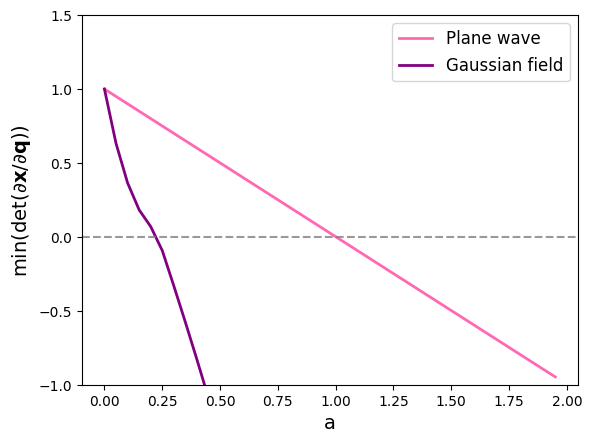

1.05
0.25


In [47]:
#plot the minimum value of det(J) as a function time 
plt.plot(d_vals, min_detJ_1d, color="hotpink", lw=2, label="Plane wave")
plt.plot(d_vals, min_detJ_3d, color="purple", lw=2, label="Gaussian field")
plt.axhline(0, color="gray", linestyle="dashed", alpha=0.8)

plt.ylim(-1, 1.5)
plt.xlabel("a", fontsize=14)
plt.ylabel(r"min$(\text{det}(\partial\mathbf{x}/\partial \mathbf{q}))$", fontsize=14)
plt.legend(fontsize=12)
plt.show()

print(np.where(np.array(min_detJ_1d) <= 0)[0][0] * 0.05)
print(np.where(np.array(min_detJ_3d) <= 0)[0][0] * 0.05)


### ZA vs leapfrog

In [11]:
#cic particle interpolation 
def cic(X, Y, Z, ngrid):
    rho = np.zeros((ngrid, ngrid, ngrid))
    #distribute each particle's mass among the 8 nearest grid cells depending how much it overlaps with each cell 
    for x, y, z in zip(X,Y,Z):
        x = np.fmod(1.0+x, 1.0)
        y = np.fmod(1.0+y, 1.0)
        z = np.fmod(1.0+z, 1.0)

        il = int(np.floor(x*ngrid))
        ir = (il+1)%ngrid
        jl = int(np.floor(y*ngrid))
        jr = (jl+1)%ngrid
        kl = int(np.floor(z*ngrid))
        kr = (kl+1)%ngrid

        dx = x*ngrid-float(il)
        dy = y*ngrid-float(jl)
        dz = z*ngrid-float(kl)

        rho[il, jl, kl] += (1-dx)*(1-dy)*(1-dz)
        rho[il, jl, kr] += (1-dx)*(1-dy)*dz
        rho[il, jr, kl] += (1-dx)*dy*(1-dz)
        rho[il, jr, kr] += (1-dx)*dy*dz
        rho[ir, jl, kl] += dx*(1-dy)*(1-dz)
        rho[ir, jl, kr] += dx*(1-dy)*dz
        rho[ir, jr, kl] += dx*dy*(1-dz)
        rho[ir, jr, kr] += dx*dy*dz

    #compute the mean density
    rhomean = len(X)/ngrid**3
    #return the density contrast 
    return rho/rhomean - 1

In [ ]:
#evolve a gaussian field up to different a 
L=1
N=64
f, dphi, d2phi = generate_gaussian_field(N,L)

#lists to store results in 
x_za_64 = []
v_za_64 = []
x_leapfrog_64 = []
v_leapfrog_64 = []
std_za_64 = []
std_leapfrog_64 = []

for a_test in [0.1, 0.3, 0.5, 1, 3, 5]:
    #run simulation
    x_za, v_za = run_simulation(dphi, d2phi, N, L, a_test, type="zeldovich")
    x_leapfrog, v_leapfrog = run_simulation(dphi, d2phi, N, L, a_test, type="leapfrog")

    #compute overdensity fields
    delta_za = cic(x_za[:,0], x_za[:,1], x_za[:,2], N)
    delta_leapfrog = cic(x_leapfrog[:,0], x_leapfrog[:,1], x_leapfrog[:,2], N)

    #append results
    x_za_64.append(x_za)
    v_za_64.append(v_za)
    x_leapfrog_64.append(x_leapfrog)
    v_leapfrog_64.append(v_leapfrog)
    std_za_64.append(np.std(delta_za))
    std_leapfrog_64.append(np.std(delta_leapfrog))


In [ ]:
#save results
np.save("x_za_64.npy", np.array(x_za_64, dtype=object))
np.save("v_za_64.npy", np.array(v_za_64, dtype=object))

np.save("x_leapfrog_64.npy", np.array(x_leapfrog_64, dtype=object))
np.save("v_leapfrog_64.npy", np.array(v_leapfrog_64, dtype=object))

np.save("std_za_64.npy", np.array(std_za_64, dtype=object))
np.save("std_leapfrog_64.npy", np.array(std_leapfrog_64, dtype=object))

In [8]:
#load results
x_za_64 = np.load("x_za_64.npy", allow_pickle=True)
v_za_64 = np.load("v_za_64.npy", allow_pickle=True)

x_leapfrog_64 = np.load("x_leapfrog_64.npy", allow_pickle=True)
v_leapfrog_64 = np.load("v_leapfrog_64.npy", allow_pickle=True)

std_za_64 = np.load("std_za_64.npy", allow_pickle=True)
std_leapfrog_64 = np.load("std_leapfrog_64.npy", allow_pickle=True)

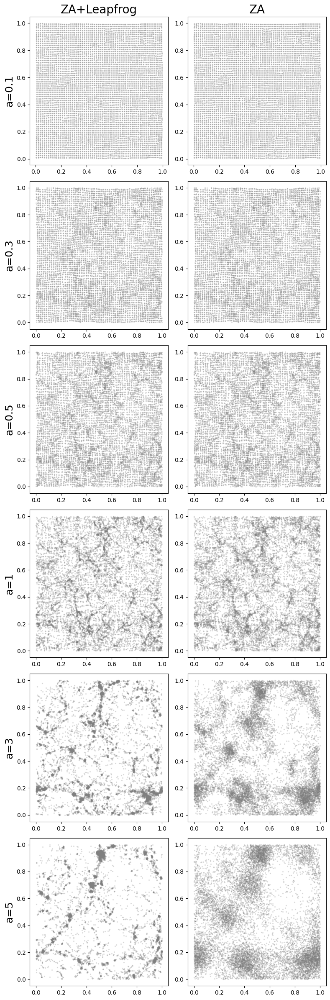

In [9]:
#plot the scattered particle positions
fig, ax = plt.subplots(6, 2, figsize=(8, 24))

a_snapshots = [0.1, 0.3, 0.5, 1, 3, 5]

for i in range(6):
    mask_leapfrog = (x_leapfrog_64[i][:,2] >= 0.48) & (x_leapfrog_64[i][:,2] <= 0.53)
    mask_za = (x_za_64[i][:,2] >= 0.48) & (x_za_64[i][:,2] <= 0.53)

    ax[i,0].scatter(x_leapfrog_64[i][:,0][mask_leapfrog], x_leapfrog_64[i][:,1][mask_leapfrog], s=2, alpha=0.2, color="gray")
    ax[i,1].scatter(x_za_64[i][:,0][mask_za], x_za_64[i][:,1][mask_za], s=2, alpha=0.2, color="gray")
    ax[i,0].set_ylabel(f"a={a_snapshots[i]}", fontsize=18)

ax[0, 0].set_title("ZA+Leapfrog", fontsize=20)
ax[0, 1].set_title("ZA", fontsize=20)

plt.tight_layout()
plt.show()

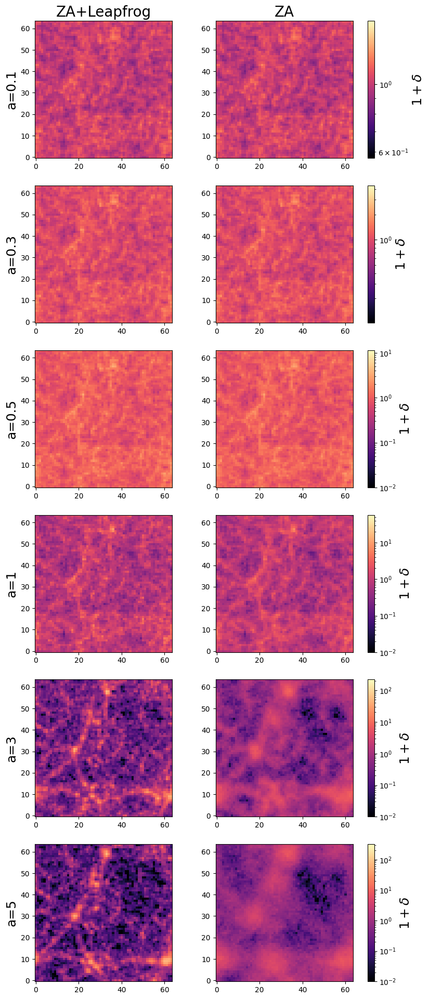

In [12]:
#plot the resulting density fields
fig, ax = plt.subplots(6, 2, figsize=(9, 24))

a_snapshots = [0.1, 0.3, 0.5, 1, 3, 5]

for i in range(6):
    delta_leapfrog = cic(x_leapfrog_64[i][:,0], x_leapfrog_64[i][:,1], x_leapfrog_64[i][:,2], 64)
    delta_za = cic(x_za_64[i][:,0], x_za_64[i][:,1], x_za_64[i][:,2], 64)

    vmin = min(delta_leapfrog.min()+1.01, delta_za.min()+1.01)
    vmax = max(delta_leapfrog.max()+1.01, delta_za.max()+1.01)

    ax[i,0].imshow(((delta_leapfrog[:, :, 30:40].mean(axis=2)) + 1.01).T, norm=LogNorm(vmin, vmax), cmap="magma", origin="lower")
    im1 = ax[i,1].imshow(((delta_za[:, :, 30:40].mean(axis=2)) + 1.01).T, norm=LogNorm(vmin, vmax), cmap="magma", origin="lower")
    ax[i,0].set_ylabel(f"a={a_snapshots[i]}", fontsize=18)
    cbar = fig.colorbar(im1, ax=[ax[i, 0], ax[i, 1]], fraction=0.046, pad=0.04)
    cbar.set_label(r"$1+\delta$", fontsize=18)
    

ax[0, 0].set_title("ZA+Leapfrog", fontsize=20)
ax[0, 1].set_title("ZA", fontsize=20)

#plt.tight_layout()
plt.show()

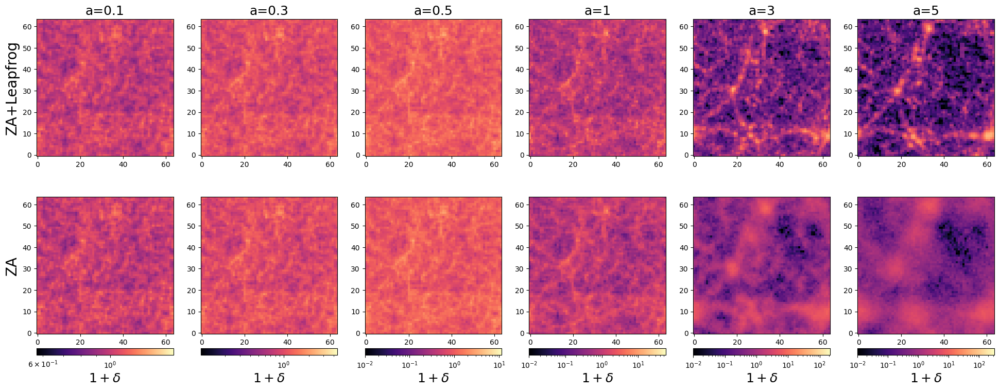

In [18]:
#plot the resulting density fields
fig, ax = plt.subplots(2, 6, figsize=(24, 9))

a_snapshots = [0.1, 0.3, 0.5, 1, 3, 5]

for i in range(6):
    delta_leapfrog = cic(x_leapfrog_64[i][:,0], x_leapfrog_64[i][:,1], x_leapfrog_64[i][:,2], 64)
    delta_za = cic(x_za_64[i][:,0], x_za_64[i][:,1], x_za_64[i][:,2], 64)

    vmin = min(delta_leapfrog.min()+1.01, delta_za.min()+1.01)
    vmax = max(delta_leapfrog.max()+1.01, delta_za.max()+1.01)

    ax[0,i].imshow(((delta_leapfrog[:, :, 30:40].mean(axis=2)) + 1.01).T, norm=LogNorm(vmin, vmax), cmap="magma", origin="lower")
    im1 = ax[1,i].imshow(((delta_za[:, :, 30:40].mean(axis=2)) + 1.01).T, norm=LogNorm(vmin, vmax), cmap="magma", origin="lower")
    ax[0,i].set_title(f"a={a_snapshots[i]}", fontsize=18)
    cbar = fig.colorbar(im1, ax=[ax[0, i], ax[1, i]], fraction=0.046, pad=0.04, orientation="horizontal")
    cbar.set_label(r"$1+\delta$", fontsize=18)
    

ax[0, 0].set_ylabel("ZA+Leapfrog", fontsize=20)
ax[1, 0].set_ylabel("ZA", fontsize=20)

#plt.tight_layout()
plt.show()

### 3D plot

In [52]:
#3d plot for final leapfrog snapshot
N=64

positions = np.array(x_leapfrog_64[5], dtype=np.float64)

#compute the density at each particle position 
density = np.zeros((N, N, N))
idx = (positions * N).astype(int) % N

for i, j, k in idx:
    density[i, j, k] += 1

density += 1.01
coords = (positions * N) % N  # fractional grid coords
particle_density = map_coordinates(density, coords.T, order=1, mode='wrap')

#keep only top percent by density
threshold = np.percentile(particle_density, 40)
mask = particle_density >= threshold
x, y, z = positions[mask, 0], positions[mask, 1], positions[mask, 2]
c = np.log10(particle_density[mask])

#set up the box
box_lines = []
edges = [([0,1],[0,0],[0,0]), ([0,1],[1,1],[0,0]), ([0,1],[0,0],[1,1]), ([0,1],[1,1],[1,1]),
        ([0,0],[0,1],[0,0]), ([1,1],[0,1],[0,0]), ([0,0],[0,1],[1,1]), ([1,1],[0,1],[1,1]),
        ([0,0],[0,0],[0,1]), ([1,1],[0,0],[0,1]), ([0,0],[1,1],[0,1]), ([1,1],[1,1],[0,1]),]

for ex, ey, ez in edges:
    box_lines.append(go.Scatter3d(
        x=ex, y=ey, z=ez,
        mode='lines',
        line=dict(color='white', width=2),
        showlegend=False))
    
#scatter particles
scatter = go.Scatter3d(
    x=x, y=y, z=z,
    mode="markers",
    marker=dict(size=1.5, color=c, colorscale="magma", opacity=0.6,
        colorbar=dict(
            title=dict(
                text="log₁₀(1+δ)",
                side='top',         
                font=dict(size=14)),
            thickness=15, len=0.75, x=0.9,),),
    showlegend=False)

fig = go.Figure(data=[scatter, *box_lines])
fig.update_layout(
    title=dict(text="ZA+Leapfrog (a=5)", x=0.05, y=0.95, font=dict(size=26, color="white")),
    width=650,                      
    height=600,                   
    paper_bgcolor='black',
    font_color='white',
    margin=dict(l=10, r=10, t=40, b=10),
    scene=dict(
        xaxis=dict(visible=False),
        yaxis=dict(visible=False),
        zaxis=dict(visible=False),
        bgcolor='black',
        aspectmode='cube',
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.2))))
fig.show()

In [53]:
#3d plot for final ZA snapshot
N=64

positions = np.array(x_za_64[5], dtype=np.float64)

#compute the density at each particle position 
density = np.zeros((N, N, N))
idx = (positions * N).astype(int) % N

for i, j, k in idx:
    density[i, j, k] += 1

density += 1.01
coords = (positions * N) % N  # fractional grid coords
particle_density = map_coordinates(density, coords.T, order=1, mode='wrap')

#keep only top percent by density
threshold = np.percentile(particle_density, 40)
mask = particle_density >= threshold
x, y, z = positions[mask, 0], positions[mask, 1], positions[mask, 2]
c = np.log10(particle_density[mask])

#set up the box
box_lines = []
edges = [([0,1],[0,0],[0,0]), ([0,1],[1,1],[0,0]), ([0,1],[0,0],[1,1]), ([0,1],[1,1],[1,1]),
        ([0,0],[0,1],[0,0]), ([1,1],[0,1],[0,0]), ([0,0],[0,1],[1,1]), ([1,1],[0,1],[1,1]),
        ([0,0],[0,0],[0,1]), ([1,1],[0,0],[0,1]), ([0,0],[1,1],[0,1]), ([1,1],[1,1],[0,1]),]

for ex, ey, ez in edges:
    box_lines.append(go.Scatter3d(
        x=ex, y=ey, z=ez,
        mode='lines',
        line=dict(color='white', width=2),
        showlegend=False))
    
#scatter particles
scatter = go.Scatter3d(
    x=x, y=y, z=z,
    mode="markers",
    marker=dict(size=1.5, color=c, colorscale="magma", opacity=0.6,
        colorbar=dict(
            title=dict(
                text="log₁₀(1+δ)",
                side='top',         
                font=dict(size=14)),
            thickness=15, len=0.75, x=0.9,),),
    showlegend=False)

fig = go.Figure(data=[scatter, *box_lines])
fig.update_layout(
    title=dict(text="ZA (a=5)", x=0.05, y=0.95, font=dict(size=26, color="white")),
    width=650,                      
    height=600,                   
    paper_bgcolor='black',
    font_color='white',
    margin=dict(l=10, r=10, t=40, b=10),
    scene=dict(
        xaxis=dict(visible=False),
        yaxis=dict(visible=False),
        zaxis=dict(visible=False),
        bgcolor='black',
        aspectmode='cube',
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.2))))
fig.show()

### Standard deviation

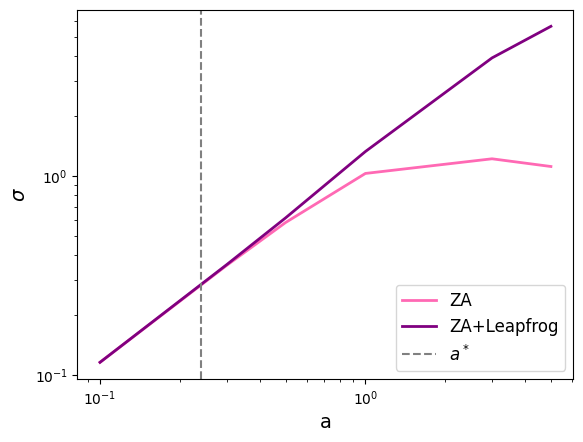

In [54]:
#plot the evolution of the standard deviation of the two fields
a_snapshots = [0.1, 0.3, 0.5, 1, 3, 5]

plt.loglog(a_snapshots, std_za_64, lw=2, color="hotpink", label="ZA")
plt.loglog(a_snapshots, std_leapfrog_64, lw=2, color="purple", label="ZA+Leapfrog")
plt.axvline(0.24, color="gray", linestyle="--", label=r"$a^*$")
plt.xlabel("a", fontsize=14)
plt.ylabel(r"$\sigma$", fontsize=14)
plt.legend(fontsize=12)
plt.show()

#N=64
#Shellcrossing time: 0.24
#Switch to leapfrog: 0.12

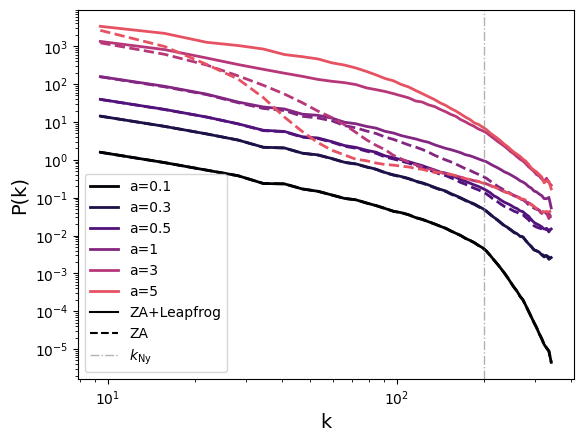

In [55]:
#compute the power spectra for the fields at different times
snapshots = [0.1, 0.3, 0.5, 1, 3, 5]
colors = plt.cm.magma(np.linspace(0, 1, len(a_snapshots)+3))

for i in range(6):
    delta_leapfrog = cic(x_leapfrog_64[i][:,0], x_leapfrog_64[i][:,1], x_leapfrog_64[i][:,2], 64)
    k, Pk_lf = compute_powerspectrum3d(delta_leapfrog, L, 64)
    plt.loglog(k, Pk_lf, color=colors[i], lw=2, ls='-', label=f"a={snapshots[i]}")

    delta_za = cic(x_za_64[i][:,0], x_za_64[i][:,1], x_za_64[i][:,2], 64)
    k, Pk_za = compute_powerspectrum3d(delta_za, L, 64)
    plt.loglog(k, Pk_za, color=colors[i], lw=2, ls='--')

plt.plot([], [], color="black", label='ZA+Leapfrog')
plt.plot([], [], color="black", linestyle="--", label='ZA')

#Nyquist frequency
k_nyq = np.pi * 64 / L
plt.axvline(k_nyq, color="gray", ls='-.', lw=1, alpha=0.6, label=r'$k_\mathrm{Ny}$')

plt.legend(fontsize=10)
plt.xlabel("k", fontsize=14)
plt.ylabel("P(k)", fontsize=14)
plt.show()